<b><font size="6" color="#E8800A">EDA · Ludovico</font></b><br>
<b><font size="4">Everything & Then Some: what the purchase data looks like before any modelling</font></b>

**Owner:** Ludovico

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>The files</font>](#files)
* [<font color='#E8800A'>Data quality</font>](#quality)
* [<font color='#E8800A'>The target</font>](#target)
* [<font color='#E8800A'>Time and repeated customers</font>](#time)
* [<font color='#E8800A'>Univariate view</font>](#univariate)
* [<font color='#E8800A'>Relationships with the target</font>](#relationships)
* [<font color='#E8800A'>Identifier-like columns and `random_noise`</font>](#identifiers)
* [<font color='#E8800A'>`clientes.csv`</font>](#clientes)
* [<font color='#E8800A'>Insights</font>](#insights)

</div>

In [24]:
# Make the project root importable so that `src` can be imported from any notebook folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "environment.yml").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not find environment.yml in any parent folder.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.paths import DATA_RAW

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, ks_2samp
from scipy.stats.contingency import association
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Same two colours as the course notebooks: blue = class 0 / train, orange = class 1 / test
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
CLASS_COLOURS = {0: PLOT_BLUE, 1: PLOT_ORANGE}
FIGSIZE = (10, 5)
RANDOM_STATE = 42
TARGET = "repeat_purchase_90d"

# <font color='#E8800A'>The files</font> <a class="anchor" id="files"></a>
[Back to TOC](#toc)

__Step 1:__ Load the three files. `ID` identifies the row, so it goes in the index.

In [26]:
train = pd.read_csv(DATA_RAW / "train.csv", index_col="ID")
test = pd.read_csv(DATA_RAW / "test.csv", index_col="ID")
clientes = pd.read_csv(DATA_RAW / "clientes.csv")

for name, frame in [("train", train), ("test", test), ("clientes", clientes)]:
    print(f"{name:9s} {frame.shape[0]:>6,} rows x {frame.shape[1]} columns")

train.head()

train      6,534 rows x 38 columns
test         986 rows x 37 columns
clientes   1,143 rows x 13 columns


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [27]:
train.describe().T


,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,0.930000,188.920000,476.740000,1087.670000,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,0.830000,175.740000,445.740000,1036.700000,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,0.760000,154.380000,389.910000,903.370000,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000,29.930000,79.740000,184.840000,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000,0.000000,0.000000,0.000000,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000,0.000000,0.000000,0.000000,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000,0.000000,13.130000,92.280000,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000,49.050000,152.540000,396.061499,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000,4.000000,11.000000,29.000000,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000,1.000000,1.000000,1.000000,5.000000e+00


**6,534 train rows, 986 test rows, 1,143 customers.** Several column names are in Portuguese (`Total a Pagar` = amount to pay, `Total Liquido` = net total, `Custo` = cost, `Portes` = shipping, `Desc_` = discount, `Imp_` = tax, `N_ Detalhes` = number of invoice lines).

__Step 2:__ Sort the columns by what they describe. Every later step works on these groups.

In [28]:
monetary = ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
            "Total Desc_ Global", "Total Desc_ Linha", "Custo"]
detail = ["N_ Detalhes", "invoice_count_current_purchase"]
history = ["days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count",
           "prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
           "prior_min_purchase_value", "prior_max_purchase_value", "prior_mean_gap_days",
           "prior_std_gap_days"]
windows = [30, 90, 180, 365]
rolling = [f"purchase_count_{w}d" for w in windows] + [f"spend_{w}d" for w in windows]
categorical = ["payment_type", "salesperson", "commercial_zone", "transport_method",
               "warehouse", "document_series"]
numeric = monetary + detail + history + rolling

groups = {
    "current monetary values": monetary,
    "current purchase detail": detail,
    "customer history": history,
    "rolling windows": rolling,
    "categoricals": categorical,
    "identifier (customer_id)": ["customer_id"],
    "date / noise": ["purchase_date", "random_noise"],
}
assigned = sum(groups.values(), []) + [TARGET]
print("columns not assigned to a group:", sorted(set(train.columns) - set(assigned)))
print("test = train minus the target:", set(train.columns) - set(test.columns) == {TARGET})
pd.Series({group: len(cols) for group, cols in groups.items()}).to_frame("columns")

columns not assigned to a group: []
test = train minus the target: True


,columns
current monetary values,8
current purchase detail,2
customer history,10
rolling windows,8
categoricals,6
identifier (customer_id),1
date / noise,2


# <font color='#E8800A'>Data quality</font> <a class="anchor" id="quality"></a>
[Back to TOC](#toc)

__Step 3:__ Where are the missing values, in train and in test?

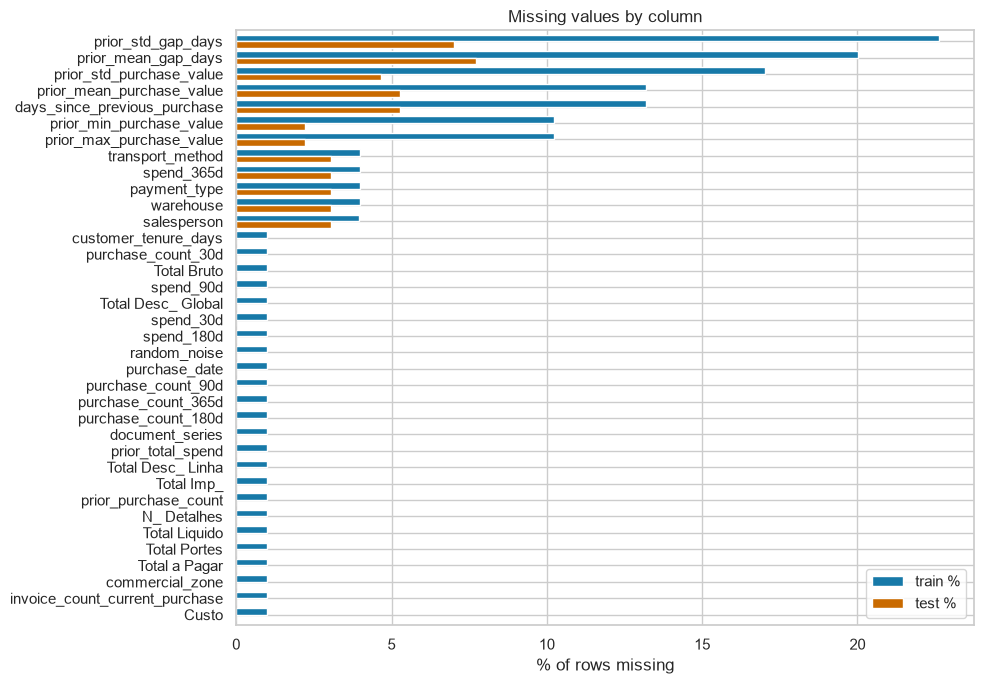

In [29]:
missing = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
missing["train %"] = (100 * missing["train"] / len(train)).round(2)
missing["test %"] = (100 * missing["test"] / len(test)).round(2)
missing = missing[(missing["train"] > 0) | (missing["test"] > 0)].sort_values("train", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
missing[["train %", "test %"]].plot.barh(ax=ax, color=[PLOT_BLUE, PLOT_ORANGE], width=0.8)
ax.invert_yaxis()
ax.set(xlabel="% of rows missing", ylabel="", title="Missing values by column")
plt.tight_layout()
plt.show()

**Three different kinds of missing values.** (1) A block of 65 train rows missing in every column (Step 4). (2) The `prior_*` gap and value statistics are missing mostly for **structural** reasons: a first purchase has no previous gap. (3) The categoricals and `spend_365d` lose about 3% each in both train and test, in **different rows**, so the missingness looks scattered rather than tied to one group of records.

__Step 4:__ The same 65 train rows seem to be missing everywhere. Check what is left in them, and whether they explain the duplicates.

In [30]:
features = monetary + detail + history + rolling + categorical + ["purchase_date", "random_noise"]
empty = train[features].isna().all(axis=1)

print(f"train rows with every feature missing: {empty.sum()}")
print("columns still filled in those rows:", train.loc[empty].columns[train.loc[empty].notna().all()].tolist())
print("their target:", train.loc[empty, TARGET].value_counts().to_dict())
print(f"test rows with every feature missing: {test[features].isna().all(axis=1).sum()}")

# ID is the index, so .duplicated() compares every other column
print(f"\nduplicated rows in train: {train.duplicated().sum()}"
      f"  -> once the empty rows are set aside: {train[~empty].duplicated().sum()}")

# From here on, `valid` is train without the empty rows (exploration only, nothing is dropped yet)
valid = train[~empty]

train rows with every feature missing: 65
columns still filled in those rows: ['repeat_purchase_90d', 'customer_id']
their target: {1: 33, 0: 32}
test rows with every feature missing: 0

duplicated rows in train: 10  -> once the empty rows are set aside: 0


**The 65 empty rows carry only `customer_id` and the target**, and they are the source of all 10 duplicated rows. They hold no information a model can use: a candidate rule for `02_cleaning` is to drop them from train (test has none).

__Step 5:__ Domain check. Amounts, counts and day intervals cannot be negative, and values around 10<sup>9</sup> are not plausible purchase values.

In [31]:
non_negative = monetary + detail + history + rolling


def domain_report(frame):
    """Count negative values and implausibly large values (>= 1e8) per column."""
    return pd.DataFrame({
        "negative": (frame[non_negative] < 0).sum(),
        ">= 1e8": (frame[non_negative] >= 1e8).sum(),
    })


report = pd.concat({"train": domain_report(train), "test": domain_report(test)}, axis=1)
report[(report > 0).any(axis=1)]

train            test       
                             negative >= 1e8 negative >= 1e8
days_since_previous_purchase       16      0        2      0
prior_mean_purchase_value          16     16        2      2
prior_mean_gap_days                16      0        2      0
spend_365d                         15     15        2      2

In [32]:
# Which values are they? Random damage spreads over many values, a placeholder piles up on few.
for column in ["days_since_previous_purchase", "prior_mean_gap_days", "prior_mean_purchase_value", "spend_365d"]:
    negatives = train.loc[train[column] < 0, column].round(2)
    huge = train.loc[train[column] >= 1e8, column]
    print(f"{column:30s} negatives: {negatives.nunique():2d} distinct values, most common {negatives.value_counts().head(2).to_dict()}"
          f" | >= 1e8: {huge.value_counts().to_dict()}")

invalid = (train[non_negative] < 0) | (train[non_negative] >= 1e8)
print(f"\ntrain rows with at least one impossible value: {invalid.any(axis=1).sum()}")

days_since_previous_purchase   negatives:  1 distinct values, most common {-4.0: 16} | >= 1e8: {}
prior_mean_gap_days            negatives:  1 distinct values, most common {-4.0: 16} | >= 1e8: {}
prior_mean_purchase_value      negatives: 16 distinct values, most common {-110.15: 1, -409.79: 1} | >= 1e8: {1000000000.0: 16}
spend_365d                     negatives: 15 distinct values, most common {-3456.32: 1, -1230.72: 1} | >= 1e8: {1000000000.0: 15}

train rows with at least one impossible value: 94


**Placeholders, not random damage.** `days_since_previous_purchase` and `prior_mean_gap_days` are always exactly **-4** (16 rows each), and `prior_mean_purchase_value` / `spend_365d` hold exactly **1,000,000,000** (15-16 rows each) plus a few negative amounts. Each problem sits in different rows (94 train rows in total), so it looks like errors injected one column at a time. The same patterns appear in test (2 rows each), so the rule must be deterministic and applied to both: impossible value → `NaN`, then imputed inside the Pipeline.

__Step 6:__ Do the invoice totals add up? Check the accounting identities between the monetary columns.

In [33]:
identities = pd.DataFrame({
    "Bruto - Desc_Linha - Desc_Global = Liquido":
        valid["Total Bruto"] - valid["Total Desc_ Linha"] - valid["Total Desc_ Global"] - valid["Total Liquido"],
    "Liquido + Imp_ = a Pagar":
        valid["Total Liquido"] + valid["Total Imp_"] - valid["Total a Pagar"],
    "Liquido + Imp_ + Portes = a Pagar":
        valid["Total Liquido"] + valid["Total Imp_"] + valid["Total Portes"] - valid["Total a Pagar"],
})
(identities.abs() > 0.05).sum().to_frame("rows breaking the identity (tolerance 0.05)")

,rows breaking the identity (tolerance 0.05)
Bruto - Desc_Linha - Desc_Global = Liquido,0
Liquido + Imp_ = a Pagar,0
Liquido + Imp_ + Portes = a Pagar,1053


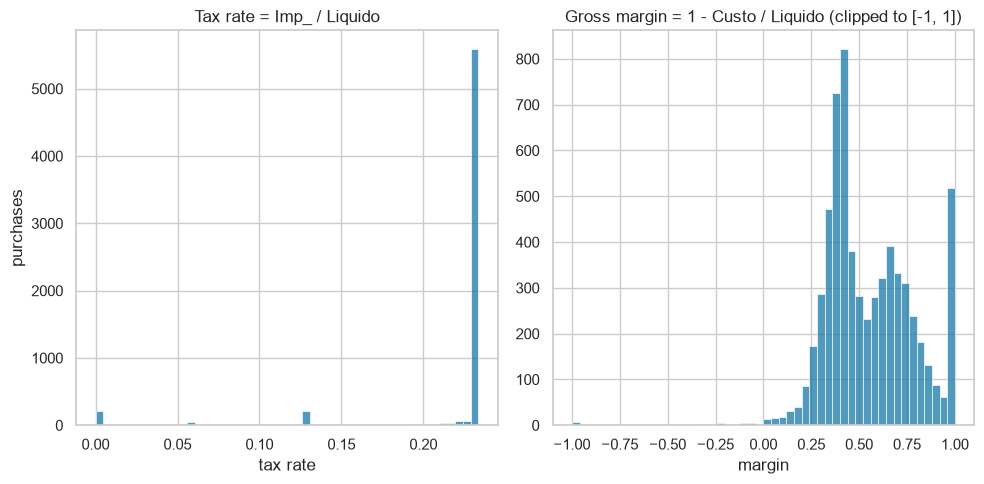

tax rate of 23%: 87.2% of purchases, 0%: 3.3%
cost equal to 0: 486 purchases | cost above the net total: 39


In [34]:
tax_rate = valid["Total Imp_"] / valid["Total Liquido"]
margin = 1 - valid["Custo"] / valid["Total Liquido"]

fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE)
sns.histplot(tax_rate, bins=50, color=PLOT_BLUE, ax=left)
left.set(title="Tax rate = Imp_ / Liquido", xlabel="tax rate", ylabel="purchases")
sns.histplot(margin.clip(-1, 1), bins=50, color=PLOT_BLUE, ax=right)
right.set(title="Gross margin = 1 - Custo / Liquido (clipped to [-1, 1])", xlabel="margin", ylabel="")
plt.tight_layout()
plt.show()

print(f"tax rate of 23%: {(tax_rate.round(2) == 0.23).mean():.1%} of purchases, 0%: {(tax_rate == 0).mean():.1%}")
print(f"cost equal to 0: {(valid['Custo'] == 0).sum()} purchases | cost above the net total: {(valid['Custo'] > valid['Total Liquido']).sum()}")

**The invoice arithmetic is clean:** `Bruto - discounts = Liquido` and `Liquido + Imp_ = a Pagar` hold in every row, so `Total Portes` (shipping) is **not** part of the amount to pay. Most purchases carry the 23% VAT rate. 486 purchases have zero cost and 39 have a cost above the net total (negative margin): plausible (free samples, sales at a loss), so flagged rather than treated as errors. The monetary columns are strongly redundant with each other.

__Step 7:__ Is the customer history internally consistent? Rolling windows are nested (30d ⊂ 90d ⊂ 180d ⊂ 365d), and a first purchase has no previous purchase.

In [35]:
nested = {}
for short, long in zip(windows[:-1], windows[1:]):
    nested[f"purchase_count_{short}d > purchase_count_{long}d"] = (valid[f"purchase_count_{short}d"] > valid[f"purchase_count_{long}d"]).sum()
    nested[f"spend_{short}d > spend_{long}d"] = (valid[f"spend_{short}d"] > valid[f"spend_{long}d"] + 0.01).sum()
pd.Series(nested).to_frame("rows breaking the nesting")

,rows breaking the nesting
purchase_count_30d > purchase_count_90d,0
spend_30d > spend_90d,0
purchase_count_90d > purchase_count_180d,0
spend_90d > spend_180d,0
purchase_count_180d > purchase_count_365d,0
spend_180d > spend_365d,15


In [36]:
first_purchase = valid["prior_purchase_count"] == 0
pd.crosstab(first_purchase, valid["days_since_previous_purchase"].isna(),
            rownames=["prior_purchase_count == 0"], colnames=["days_since_previous_purchase is missing"])

days_since_previous_purchase is missing,False,True
prior_purchase_count == 0,,
False,5673,193
True,0,603


**The rolling windows are consistent** except for 15 rows where `spend_365d` is broken (the placeholder rows of Step 5). **All 603 first purchases** have a missing `days_since_previous_purchase`: that missing value means *no previous purchase*, which is information, so a missing indicator is worth testing in `04_preprocessing`. The other 193 missing values in that column are not first purchases and look like injected noise.

# <font color='#E8800A'>The target</font> <a class="anchor" id="target"></a>
[Back to TOC](#toc)

__Step 8:__ Look at the target before looking at anything against it. The metric is F1 on class 1, so the trivial "always 1" prediction sets the floor.

In [37]:
balance = train[TARGET].value_counts().sort_index()
share = balance / balance.sum()
print(balance.to_frame("rows").assign(share=share.round(3)).to_string())

p = share[1]
print(f"\n'always predict 1': precision {p:.3f}, recall 1.000, F1 {2 * p / (1 + p):.3f}")

                     rows  share
repeat_purchase_90d             
0                    2880  0.441
1                    3654  0.559

'always predict 1': precision 0.559, recall 1.000, F1 0.717


**55.9% of purchases are followed by another one within 90 days.** The classes are not severely imbalanced, but the trivial "always 1" answer already reaches **F1 = 0.717**: this is the floor every model must beat, and it shows why the decision threshold needs tuning.

# <font color='#E8800A'>Time and repeated customers</font> <a class="anchor" id="time"></a>
[Back to TOC](#toc)

__Step 9:__ How do train and test sit in time?

train: 2015-07-11 -> 2025-02-15
test:  2025-05-24 -> 2026-10-06
gap between the last train purchase and the first test purchase: 98 days


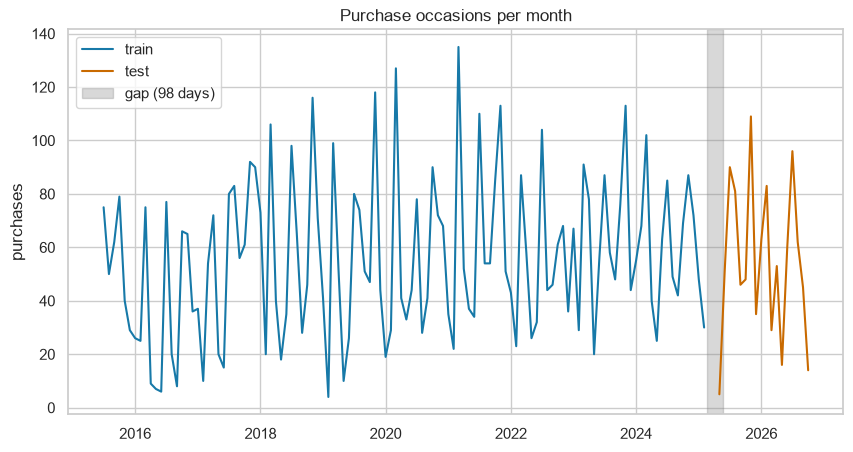

In [38]:
train_dates = pd.to_datetime(train["purchase_date"])
test_dates = pd.to_datetime(test["purchase_date"])
gap_days = (test_dates.min() - train_dates.max()).days

print(f"train: {train_dates.min():%Y-%m-%d} -> {train_dates.max():%Y-%m-%d}")
print(f"test:  {test_dates.min():%Y-%m-%d} -> {test_dates.max():%Y-%m-%d}")
print(f"gap between the last train purchase and the first test purchase: {gap_days} days")

monthly = pd.DataFrame({
    "train": train_dates.dt.to_period("M").value_counts(),
    "test": test_dates.dt.to_period("M").value_counts(),
}).sort_index()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(monthly.index, monthly["train"], color=PLOT_BLUE, label="train")
ax.plot(monthly.index, monthly["test"], color=PLOT_ORANGE, label="test")
ax.axvspan(train_dates.max(), test_dates.min(), color="grey", alpha=0.3, label=f"gap ({gap_days} days)")
ax.set(title="Purchase occasions per month", ylabel="purchases")
ax.legend()
plt.show()

**Train covers 2015-07 → 2025-02, test 2025-05 → 2026-10, with a 98-day gap in between**, just over the 90-day target horizon. Monthly volume is very irregular. The validation scheme should copy this setting: train on the past, validate on a later block, with a gap of at least 90 days (`03_validation`).

__Step 10:__ Is the share of repeat purchases stable over the years?

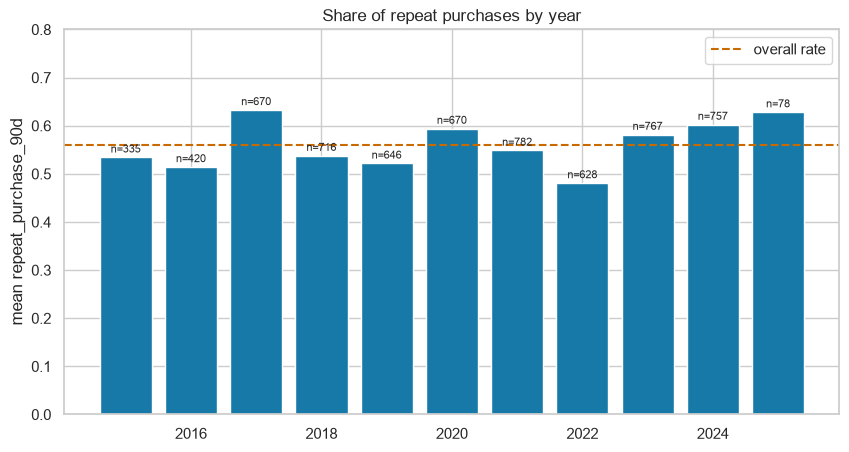

In [39]:
year = train_dates.dt.year.astype("Int64")
by_year = train.groupby(year)[TARGET].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(by_year.index.astype(int), by_year["mean"], color=PLOT_BLUE)
ax.axhline(train[TARGET].mean(), color=PLOT_ORANGE, ls="--", label="overall rate")
for y, row in by_year.iterrows():
    ax.text(y, row["mean"] + 0.01, f"n={row['size']:.0f}", ha="center", fontsize=8)
ax.set(title="Share of repeat purchases by year", ylabel=f"mean {TARGET}", ylim=(0, 0.8))
ax.legend()
plt.show()

**The repeat rate drifts between about 0.48 and 0.63 from year to year**, with no clear trend. 2025 has only 78 train rows (January-February), so its rate is not reliable. A time-based validation will show whether this drift hurts the models.

__Step 11:__ How often do customers come back, and are test customers already known from train?

customers: 610 in train, 206 in test
rows per train customer: median 4, max 277
the 10 biggest customers hold 17.5% of train rows
test rows whose customer already appears in train: 94.5%


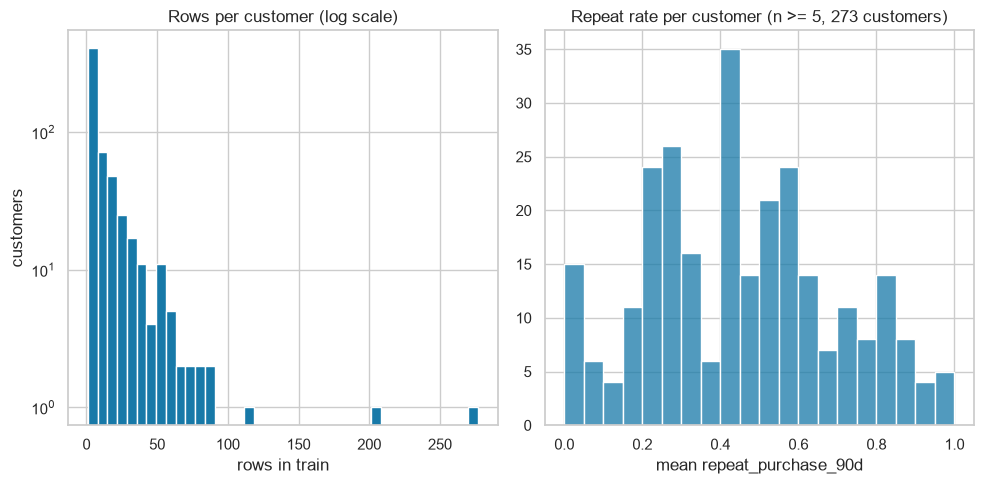

In [40]:
rows_per_customer = train.groupby("customer_id").size()
seen = test["customer_id"].isin(train["customer_id"])

print(f"customers: {rows_per_customer.size} in train, {test['customer_id'].nunique()} in test")
print(f"rows per train customer: median {rows_per_customer.median():.0f}, max {rows_per_customer.max()}")
print(f"the 10 biggest customers hold {rows_per_customer.nlargest(10).sum() / len(train):.1%} of train rows")
print(f"test rows whose customer already appears in train: {seen.mean():.1%}")

# Repeat rate per customer (customers with at least 5 rows): how different are customers from each other?
per_customer = train.groupby("customer_id")[TARGET].agg(["mean", "size"]).query("size >= 5")

fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE)
left.hist(rows_per_customer, bins=40, color=PLOT_BLUE)
left.set_yscale("log")
left.set(title="Rows per customer (log scale)", xlabel="rows in train", ylabel="customers")
sns.histplot(per_customer["mean"], bins=20, color=PLOT_BLUE, ax=right)
right.set(title=f"Repeat rate per customer (n >= 5, {len(per_customer)} customers)", xlabel=f"mean {TARGET}", ylabel="")
plt.tight_layout()
plt.show()

**Customers repeat a lot:** 610 customers for 6,534 rows, a median of 4 rows each and up to 277. The 10 biggest customers hold 17.5% of train. **94.5% of test rows belong to customers already in train**, and customers differ a lot in their own repeat rate (right plot). Customer history features should therefore be informative. A pure group split by customer would be pessimistic compared to the real test, since almost all test customers are known.

__Step 12:__ Check the target definition: is the next row of the same customer, inside train, within 90 days whenever the target is 1?

In [41]:
ordered = valid.assign(date=train_dates).sort_values(["customer_id", "date"])
ordered["days_to_next_row"] = (ordered.groupby("customer_id")["date"].shift(-1) - ordered["date"]).dt.days
with_next = ordered.dropna(subset=["days_to_next_row"])

pd.crosstab(with_next["days_to_next_row"] <= 90, with_next[TARGET],
            rownames=["next row of the customer within 90 days"], colnames=[TARGET])

repeat_purchase_90d,0,1
next row of the customer within 90 days,,
False,2282,15
True,0,3565


<div class="alert alert-block alert-warning">

**The target is almost exactly "the next purchase of the same customer is within 90 days".** When a later row of the customer exists in train within 90 days, the target is always 1; the 15 exceptions are probably purchases not present in the file. This confirms the definition, and it is also a **leakage warning**: the row order of the *future* (including other test rows) is information a real model would not have at prediction time. Features must only use the past. Decision for the team to log in `docs/decisions.md`.

</div>

# <font color='#E8800A'>Univariate view</font> <a class="anchor" id="univariate"></a>
[Back to TOC](#toc)

__Step 13:__ Summary statistics of the numeric columns. For the exploration only, the impossible values found in Step 5 are masked so they do not distort the statistics (the real rule belongs to `02_cleaning`).

In [42]:
explore = valid.copy()
explore[non_negative] = explore[non_negative].mask((explore[non_negative] < 0) | (explore[non_negative] >= 1e8))

summary = explore[numeric].describe().T[["mean", "50%", "min", "max"]]
summary["skew"] = explore[numeric].skew()
summary["% zeros"] = 100 * (explore[numeric] == 0).mean()
summary.sort_values("skew", ascending=False).round(2)

,mean,50%,min,max,skew,% zeros
Total Desc_ Global,0.35,0.00,0.00,218.49,27.46,98.30
prior_max_purchase_value,2946.38,1783.24,3.31,267526.19,21.34,0.00
prior_mean_purchase_value,957.93,724.90,3.31,72937.16,21.20,0.00
Total Portes,1.15,0.00,0.00,181.06,19.55,83.72
spend_365d,5777.74,2426.60,0.00,522933.21,18.55,12.52
prior_mean_gap_days,96.18,68.61,1.00,3199.00,9.31,0.00
prior_std_gap_days,74.14,50.64,0.00,2212.54,7.77,0.02
days_since_previous_purchase,101.83,57.00,1.00,3199.00,6.53,0.00
invoice_count_current_purchase,1.07,1.00,1.00,5.00,6.44,0.00
Total Desc_ Linha,112.47,13.13,0.00,4103.44,5.92,37.73


**Almost every numeric column is right-skewed** (mean well above the median), several are mostly zeros (`Total Desc_ Global` 98%, `Total Portes` 84%) and could be turned into simple flags. `customer_tenure_days` is the only column close to symmetric.

__Step 14:__ The same skew as a picture, on the raw scale and after `log1p`.

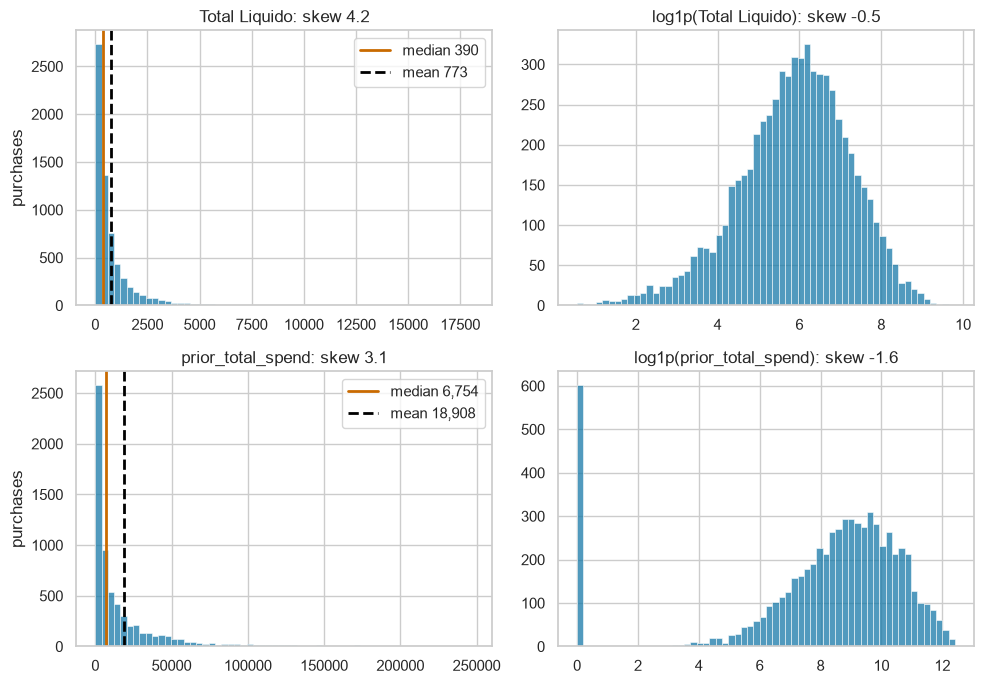

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, column in enumerate(["Total Liquido", "prior_total_spend"]):
    values = explore[column].dropna()
    sns.histplot(values, bins=60, color=PLOT_BLUE, ax=axes[row, 0])
    axes[row, 0].axvline(values.median(), color=PLOT_ORANGE, lw=2, label=f"median {values.median():,.0f}")
    axes[row, 0].axvline(values.mean(), color="black", ls="--", lw=2, label=f"mean {values.mean():,.0f}")
    axes[row, 0].set(title=f"{column}: skew {values.skew():.1f}", xlabel="", ylabel="purchases")
    axes[row, 0].legend()
    sns.histplot(np.log1p(values), bins=60, color=PLOT_BLUE, ax=axes[row, 1])
    axes[row, 1].set(title=f"log1p({column}): skew {np.log1p(values).skew():.1f}", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

**`log1p` removes most of the skew** in monetary columns. Worth testing in `04_preprocessing` for distance-based and linear models (KNN, logistic regression); tree models do not need it.

__Step 15:__ Categorical columns: how many levels, how dominant the top one is, and whether test brings levels never seen in train.

In [44]:
rows = []
for column in categorical:
    counts = train[column].value_counts()
    unseen = test[column].notna() & ~test[column].isin(counts.index)
    rows.append({
        "column": column,
        "levels": counts.size,
        "top level share": round(counts.iloc[0] / counts.sum(), 3),
        "levels with < 30 rows": int((counts < 30).sum()),
        "test levels unseen in train": test.loc[unseen, column].nunique(),
        "test rows with an unseen level": int(unseen.sum()),
    })
pd.DataFrame(rows).set_index("column")

,levels,top level share,levels with < 30 rows,test levels unseen in train,test rows with an unseen level
column,,,,,
payment_type,9,0.728,4,3,3
salesperson,9,0.646,3,0,0
commercial_zone,5,0.968,2,2,209
transport_method,80,0.178,51,2,63
warehouse,2,0.997,1,1,7
document_series,3,0.423,0,0,0


**The categoricals are dominated by one level** (`warehouse` 99.7%, `commercial_zone` 96.8%), so they carry little variation. `transport_method` has 80 levels, 51 of them with fewer than 30 rows: one-hot would create many sparse columns, so rare-level grouping or target encoding is needed. **Test contains unseen levels**: `commercial_zone` alone has 209 test rows with a level never seen in train, so encoders must handle unknown categories (`handle_unknown`).

# <font color='#E8800A'>Relationships with the target</font> <a class="anchor" id="relationships"></a>
[Back to TOC](#toc)

__Step 16:__ Which numeric columns move with the target? Spearman correlation, because the columns are heavily skewed.

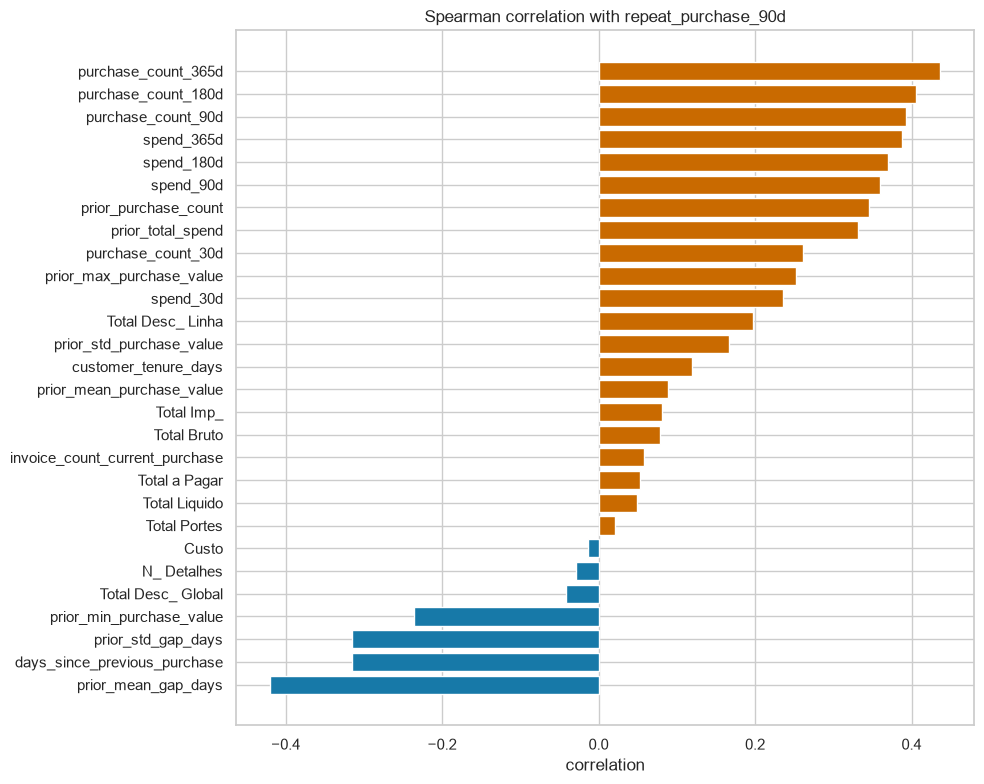

In [45]:
corr = explore[numeric].corrwith(explore[TARGET], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(corr.index, corr.values, color=[PLOT_ORANGE if v > 0 else PLOT_BLUE for v in corr.values])
ax.set(title=f"Spearman correlation with {TARGET}", xlabel="correlation")
plt.tight_layout()
plt.show()

**The strongest signals are frequency and recency.** Recent purchase counts (`purchase_count_365d` ρ ≈ 0.44, `purchase_count_180d` ≈ 0.41) and spend windows go up with the target; the typical gap between purchases (`prior_mean_gap_days` ρ ≈ -0.42) and `days_since_previous_purchase` (≈ -0.31) go down. The current invoice amounts are almost unrelated to the target (|ρ| < 0.1).

__Step 17:__ Distributions of the strongest signals by class (log scale).

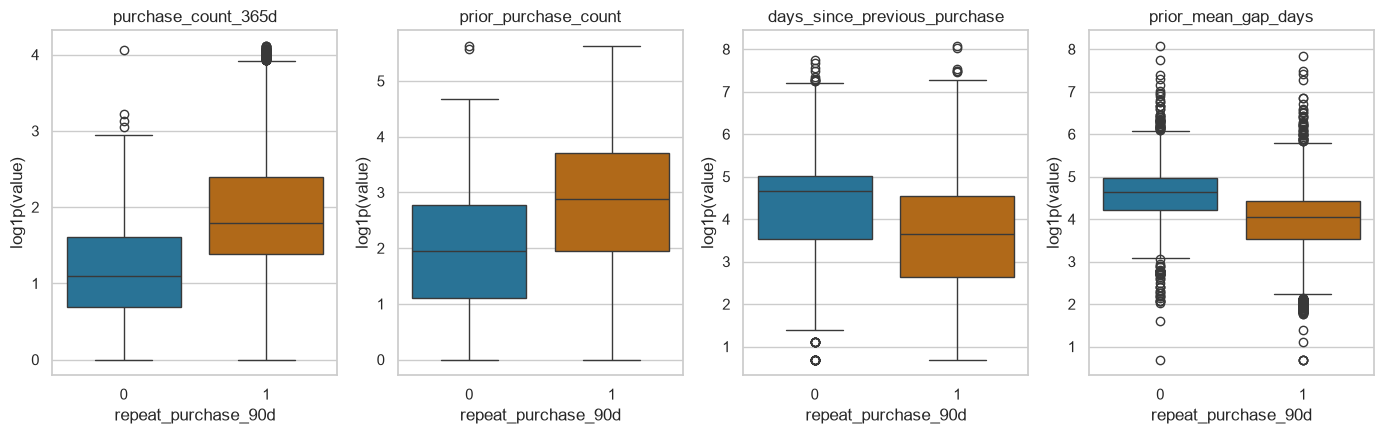

In [46]:
key_features = ["purchase_count_365d", "prior_purchase_count", "days_since_previous_purchase", "prior_mean_gap_days"]

fig, axes = plt.subplots(1, len(key_features), figsize=(14, 4.5))
for ax, column in zip(axes, key_features):
    sns.boxplot(data=explore, x=TARGET, y=np.log1p(explore[column]), hue=TARGET,
                palette=CLASS_COLOURS, legend=False, ax=ax)
    ax.set(title=column, ylabel="log1p(value)", xlabel=TARGET)
plt.tight_layout()
plt.show()

**The two classes separate clearly** on purchase frequency and on the usual gap between purchases: customers who repeat buy more often and wait less between orders. This is the classic recency/frequency pattern of customer analytics, and it suggests features such as *days since last purchase relative to the customer's usual gap*.

__Step 18:__ Categorical columns against the target: Cramér's V (0 = no association, 1 = perfect) and the repeat rate by level.

In [47]:
rows = []
for column in categorical:
    table = pd.crosstab(train[column].fillna("missing"), train[TARGET])
    chi2, p, _, expected = chi2_contingency(table)
    rows.append({
        "feature": column,
        "Cramér's V": association(table, method="cramer", correction=True),
        "p": p,
        "min expected count": expected.min(),
    })
pd.DataFrame(rows).set_index("feature").sort_values("Cramér's V", ascending=False).round(4)

,Cramér's V,p,min expected count
feature,,,
transport_method,0.2841,0.0000,0.4408
payment_type,0.2329,0.0000,1.7631
salesperson,0.1994,0.0000,1.3223
commercial_zone,0.0643,0.0001,0.4408
warehouse,0.0342,0.0221,9.2562
document_series,0.0108,0.8584,28.6501


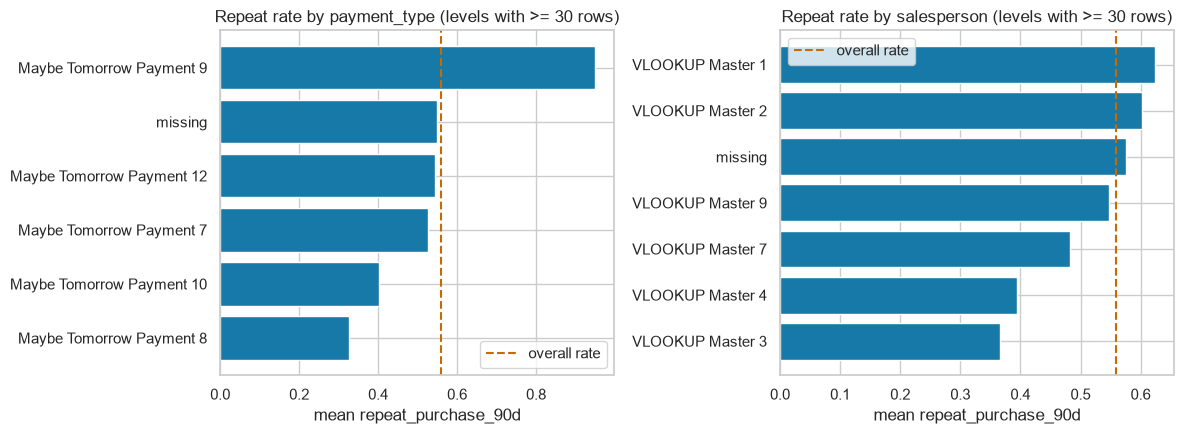

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, ["payment_type", "salesperson"]):
    rate = (train.assign(level=train[column].fillna("missing"))
            .groupby("level")[TARGET].agg(["mean", "size"])
            .query("size >= 30").sort_values("mean"))
    ax.barh(rate.index, rate["mean"], color=PLOT_BLUE)
    ax.axvline(train[TARGET].mean(), color=PLOT_ORANGE, ls="--", label="overall rate")
    ax.set(title=f"Repeat rate by {column} (levels with >= 30 rows)", xlabel=f"mean {TARGET}")
    ax.legend()
plt.tight_layout()
plt.show()

**`transport_method`, `payment_type` and `salesperson` are associated with the target** (Cramér's V 0.20-0.28), but several levels are tiny (min expected counts < 5), so their V is inflated and the test is not fully reliable. One level stands out: **`Maybe Tomorrow Payment 9` repeats 95% of the time** (502 rows), probably a payment arrangement used by regular customers. `document_series` carries no signal (V ≈ 0.01, p = 0.86).

__Step 19:__ Redundancy between history and rolling-window features.

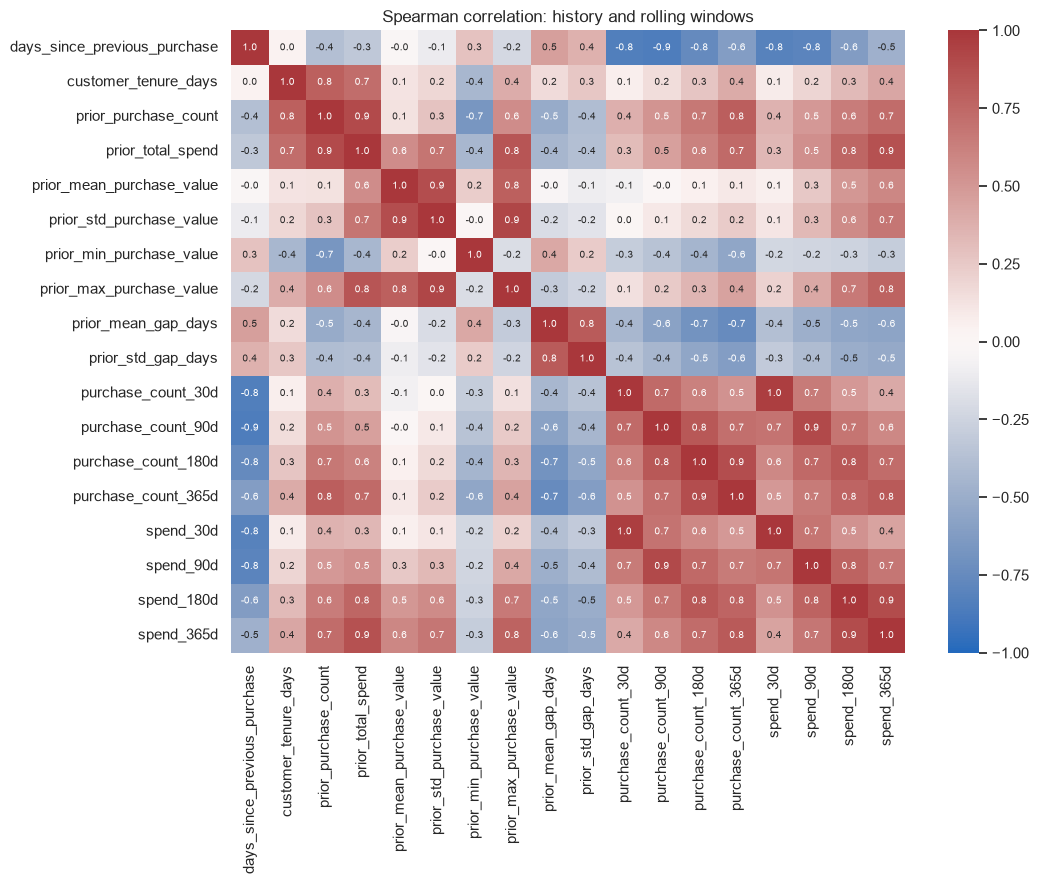

pairs with |rho| >= 0.9:
purchase_count_30d        spend_30d                   0.965
prior_std_purchase_value  prior_max_purchase_value    0.923
purchase_count_90d        spend_90d                   0.909
prior_purchase_count      prior_total_spend           0.903


In [49]:
redundancy = explore[history + rolling].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(redundancy, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax)
ax.set(title="Spearman correlation: history and rolling windows")
plt.tight_layout()
plt.show()

pairs = redundancy.where(np.triu(np.ones(redundancy.shape, dtype=bool), k=1)).stack()
print("pairs with |rho| >= 0.9:")
print(pairs[pairs.abs() >= 0.9].sort_values(ascending=False).round(3).to_string())

**Several pairs are nearly duplicates** (count vs spend in the same window, `prior_purchase_count` vs `prior_total_spend`, ρ ≥ 0.9). This is a job for the filter step in `05_features`: keep one of each pair, or combine them (e.g. average spend per purchase in a window).

# <font color='#E8800A'>Identifier-like columns and `random_noise`</font> <a class="anchor" id="identifiers"></a>
[Back to TOC](#toc)

__Step 20:__ The brief says `random_noise` is a decoy. Test it instead of assuming it: same distribution in both classes? More information than a shuffled copy of itself?

KS test between the two classes: statistic 0.023, p = 0.351
                       mutual information with the target
random_noise                                       0.0049
random_noise shuffled                              0.0000
purchase_count_365d                                0.1260


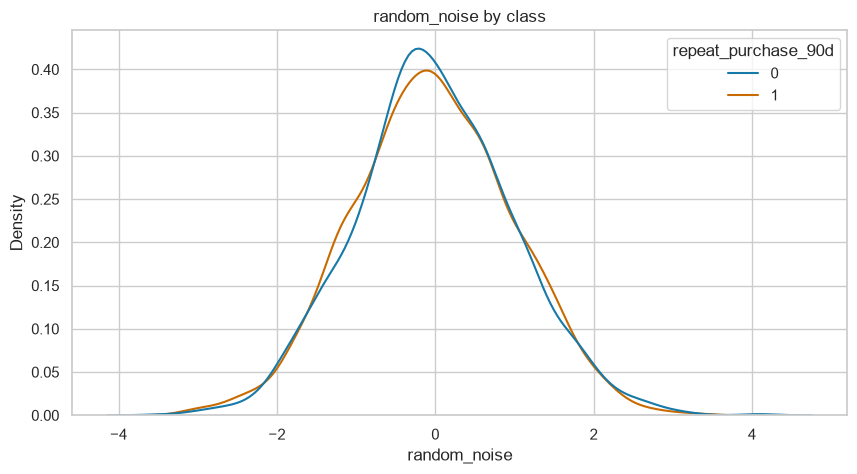

In [50]:
noise = valid[["random_noise", TARGET]].dropna()
ks = ks_2samp(noise.loc[noise[TARGET] == 0, "random_noise"], noise.loc[noise[TARGET] == 1, "random_noise"])

rng = np.random.default_rng(RANDOM_STATE)
candidates = pd.DataFrame({
    "random_noise": noise["random_noise"],
    "random_noise shuffled": rng.permutation(noise["random_noise"].to_numpy()),
    "purchase_count_365d": explore.loc[noise.index, "purchase_count_365d"].fillna(0),
})
mi = mutual_info_classif(candidates, noise[TARGET], random_state=RANDOM_STATE)

print(f"KS test between the two classes: statistic {ks.statistic:.3f}, p = {ks.pvalue:.3f}")
print(pd.Series(mi, index=candidates.columns).round(4).to_frame("mutual information with the target").to_string())

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.kdeplot(data=noise, x="random_noise", hue=TARGET, palette=CLASS_COLOURS, common_norm=False, ax=ax)
ax.set(title="random_noise by class")
plt.show()

**`random_noise` behaves like noise:** the KS test finds no difference between the classes (p = 0.35), and its mutual information with the target is close to that of a shuffled copy and far below a real feature. Expected decision: drop it, citing this evidence.

__Step 21:__ `ID` and `customer_id` are numbers, but are they also information? Check them against the target and against time.

In [51]:
check = pd.DataFrame({
    "ID": valid.index,
    "customer_id": valid["customer_id"].to_numpy(),
    "date": train_dates[~empty].map(pd.Timestamp.toordinal).to_numpy(),
    TARGET: valid[TARGET].to_numpy(),
})
check.corr(method="spearman").loc[["ID", "customer_id"], [TARGET, "date"]].round(3)

,repeat_purchase_90d,date
ID,0.012,0.011
customer_id,-0.116,-0.022


**`ID` is unrelated to both the target and time.** `customer_id` shows a weak correlation with the target (ρ ≈ -0.12): this does not mean the number means anything, only that some customers repeat more than others. The customer effect should reach the model through the history features, not through the raw identifier, which would not generalise and is high-cardinality. `customer_id` stays as the grouping key for validation.

# <font color='#E8800A'>`clientes.csv`</font> <a class="anchor" id="clientes"></a>
[Back to TOC](#toc)

__Step 22:__ Profile the optional customer table: coverage of the join, missing values, and which columns are just identifiers.

In [52]:
print(f"{len(clientes):,} rows, {clientes['customer_id'].nunique():,} distinct customer_id")
print(f"train customers found in clientes: {train['customer_id'].isin(clientes['customer_id']).mean():.1%}")
print(f"test customers found in clientes:  {test['customer_id'].isin(clientes['customer_id']).mean():.1%}")

pd.DataFrame({
    "missing %": (100 * clientes.isna().mean()).round(1),
    "distinct values": clientes.nunique(),
    "distinct / rows": (clientes.nunique() / len(clientes)).round(2),
}).sort_values("distinct / rows", ascending=False)

1,143 rows, 1,143 distinct customer_id
train customers found in clientes: 100.0%
test customers found in clientes:  100.0%


,missing %,distinct values,distinct / rows
customer_id,0.0,1143,1.00
company_name,0.0,1141,1.00
address,0.5,1120,0.98
postal_code,14.9,828,0.72
street,52.3,511,0.45
city,47.8,417,0.36
postal_area,6.2,271,0.24
municipality,13.9,183,0.16
commercial_region,10.0,37,0.03
country_or_region,0.0,11,0.01


**The join is complete** (every train and test customer is in `clientes.csv`, one row per customer), but most columns are not usable: `customer_type` is 100% missing, `company_name` and `address` are unique per customer (pure identifiers), `street`, `city` and `island` are about half missing. The candidates are `customer_since_year`, `country_or_region` and possibly `commercial_region`.

__Step 23:__ Join on `customer_id` and look at the two columns that could plausibly matter: customer seniority and country.

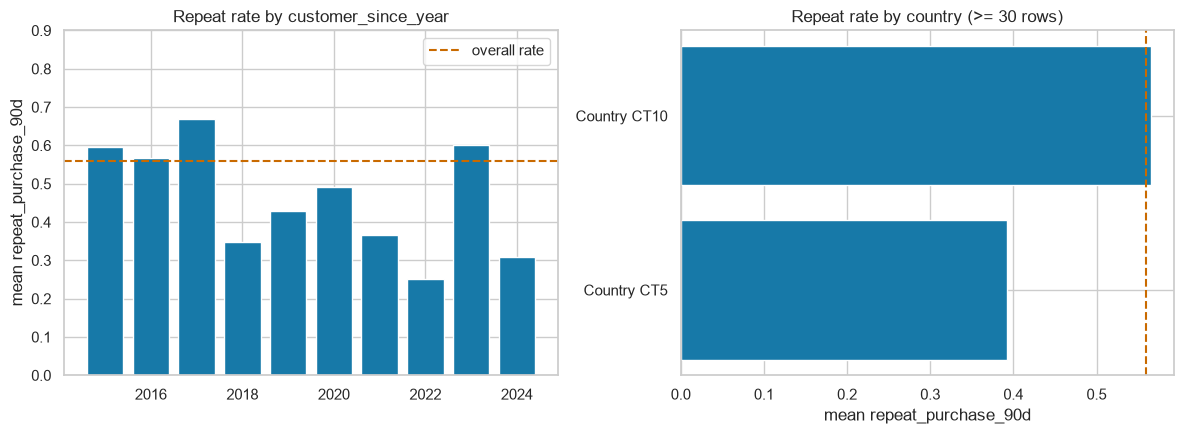

customer_since_year      2015     2016     2017     2018     2019     2020     2021     2022     2023    2024
mean                    0.595    0.567    0.668    0.349    0.428    0.491    0.365    0.252    0.602   0.308
size                 3573.000  605.000  885.000  467.000  278.000  273.000  208.000  111.000  108.000  26.000


In [53]:
merged = train.join(clientes.set_index("customer_id"), on="customer_id")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
by_since = merged.groupby("customer_since_year")[TARGET].agg(["mean", "size"])
left.bar(by_since.index, by_since["mean"], color=PLOT_BLUE)
left.axhline(train[TARGET].mean(), color=PLOT_ORANGE, ls="--", label="overall rate")
left.set(title="Repeat rate by customer_since_year", ylabel=f"mean {TARGET}", ylim=(0, 0.9))
left.legend()

by_country = (merged.groupby("country_or_region")[TARGET].agg(["mean", "size"])
              .query("size >= 30").sort_values("mean"))
right.barh(by_country.index.str.split(":").str[0], by_country["mean"], color=PLOT_BLUE)
right.axvline(train[TARGET].mean(), color=PLOT_ORANGE, ls="--")
right.set(title="Repeat rate by country (>= 30 rows)", xlabel=f"mean {TARGET}")
plt.tight_layout()
plt.show()

print(by_since.round(3).T.to_string())

**Older customers repeat more**: customers since 2015-2017 repeat 57-67% of the time, while most later cohorts are between 25% and 49% (2023 is an exception, with only 108 rows). `customer_since_year` overlaps with `customer_tenure_days`, so test whether it adds anything beyond tenure. The two countries with enough rows differ (≈ 0.56 vs ≈ 0.39), but most rows come from one country.

# <font color='#E8800A'>Insights</font> <a class="anchor" id="insights"></a>
[Back to TOC](#toc)

| # | Finding | Action | Where |
|---|---|---|---|
| 1 | 65 train rows are empty except `customer_id` and target; they cause all 10 duplicates | Drop them from train, document it | `02_cleaning`, `decisions.md` |
| 2 | Placeholders: -4 in day intervals, 1e9 in mean value / `spend_365d`, in train **and** test | Deterministic rule: value → `NaN` | `02_cleaning` |
| 3 | Missing day gaps are structural for the 603 first purchases | Test missing indicators; `prior_purchase_count == 0` as a flag | `04_preprocessing` |
| 4 | ~3% scattered missing values in categoricals and `spend_365d` | Impute inside the Pipeline | `04_preprocessing` |
| 5 | `Total a Pagar = Liquido + Imp_`; monetary columns redundant | Keep few amounts; ratios (margin, discount share) | `05_features` |
| 6 | Test is after train with a 98-day gap; repeat rate drifts by year | Time-ordered validation with a ≥ 90-day gap | `03_validation` |
| 7 | 94.5% of test rows are from known customers; customers differ a lot | Group-aware check, but not a pure group split | `03_validation` |
| 8 | Target = next purchase within 90 days | Features must only use the past: no information from later rows | `decisions.md` |
| 9 | F1 of "always 1" = 0.717 | Baseline to beat; tune the threshold | `06_models` |
| 10 | Strong skew, many zero-inflated columns | `log1p` / robust scaling for linear and KNN models; zero flags | `04_preprocessing` |
| 11 | Frequency and recency are the strongest signals | Recency relative to usual gap, activity trend between windows | `05_features` |
| 12 | Near-duplicate history/rolling pairs (ρ ≥ 0.9) | Filter step: keep one per pair | `05_features` |
| 13 | Dominant / rare / unseen categorical levels; Payment 9 repeats 95% | Rare-level grouping, `handle_unknown`, target encoding for `transport_method` | `04_preprocessing` |
| 14 | `random_noise` carries no signal; `ID` unrelated; `customer_id` is an identifier | Drop `random_noise` and `ID`; `customer_id` only as group key | `05_features` |
| 15 | `clientes.csv`: only `customer_since_year` and country look useful | Test them against tenure; drop identifiers and empty columns | `05_features` |